# Car Price Prediction with Machine Learning

**Objective:** Predict the selling price of a used car from features such as brand, age, mileage, fuel type, and transmission.

**Dataset:** *Vehicle dataset from CarDekho* (301 used car listings, India) — the dataset suggested in the task brief.
Source: `nehalbirla/vehicle-dataset-from-cardekho` on Kaggle.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

---


## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42


## 2. Load the Dataset

The dataset used here is the CarDekho used-car dataset (301 listings). It includes the car name,
manufacturing year, selling price, present (ex-showroom) price, kilometers driven, fuel type,
seller type, transmission, and number of previous owners.


In [2]:
df = pd.read_csv("car_data.csv")
print("Shape:", df.shape)
df.head()


Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [4]:
df.describe(include="all")


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,97,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.644115,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


## 3. Data Cleaning

Steps:
- Check and handle null values
- Remove duplicate rows
- Standardize inconsistent categorical values (e.g., casing/whitespace in `Fuel_Type`,
  `Seller_Type`, `Transmission`)


In [5]:
# --- Null values ---
print("Null values per column:")
print(df.isnull().sum())


Null values per column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [6]:
# --- Duplicates ---
n_dupes = df.duplicated().sum()
print(f"Duplicate rows found: {n_dupes}")
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)


Duplicate rows found: 2
Shape after dropping duplicates: (299, 9)


In [7]:
# --- Standardize categorical text (lowercase/strip so 'Petrol' and 'petrol'
# or stray whitespace are treated as the same category) ---
categorical_cols = ["Fuel_Type", "Seller_Type", "Transmission", "Car_Name"]

for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

# Title-case the label columns (keeps a single canonical spelling per category)
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    df[col] = df[col].str.title()

print(df["Fuel_Type"].unique())
print(df["Seller_Type"].unique())
print(df["Transmission"].unique())


['Petrol' 'Diesel' 'Cng']
['Dealer' 'Individual']
['Manual' 'Automatic']


In [8]:
# --- Sanity checks on numeric ranges ---
print("Year range:", df["Year"].min(), "-", df["Year"].max())
print("Any negative prices or kms?",
      (df[["Selling_Price", "Present_Price", "Kms_Driven"]] < 0).any().any())


Year range: 2003 - 2018
Any negative prices or kms? False


## 4. Feature Engineering

- `Car_Age` = current year − year of manufacture
- `Brand` = first word extracted from `Car_Name`
- Drop `Car_Name` and `Year` once `Brand` and `Car_Age` are derived from them


In [9]:
CURRENT_YEAR = 2026  # dataset reference year for age calculation

df["Car_Age"] = CURRENT_YEAR - df["Year"]

# Brand = first token of the car name, lower-cased for consistency
df["Brand"] = df["Car_Name"].str.split().str[0].str.lower()

# A few multi-word brand names in this dataset get folded into a broader "other" bucket
# if they appear only once, to avoid a very high-cardinality category
brand_counts = df["Brand"].value_counts()
rare_brands = brand_counts[brand_counts == 1].index
df["Brand"] = df["Brand"].where(~df["Brand"].isin(rare_brands), "other")

df[["Car_Name", "Year", "Car_Age", "Brand"]].head(10)


,Car_Name,Year,Car_Age,Brand
0,ritz,2014,12,ritz
1,sx4,2013,13,sx4
2,ciaz,2017,9,ciaz
3,wagon r,2011,15,wagon
4,swift,2014,12,swift
5,vitara brezza,2018,8,other
6,ciaz,2015,11,ciaz
7,s cross,2015,11,other
8,ciaz,2016,10,ciaz
9,ciaz,2015,11,ciaz


In [10]:
df.drop(columns=["Car_Name", "Year"], inplace=True)
df.head()


,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Brand
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,ritz
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,sx4
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,ciaz
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,wagon
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,swift


## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of Selling Prices

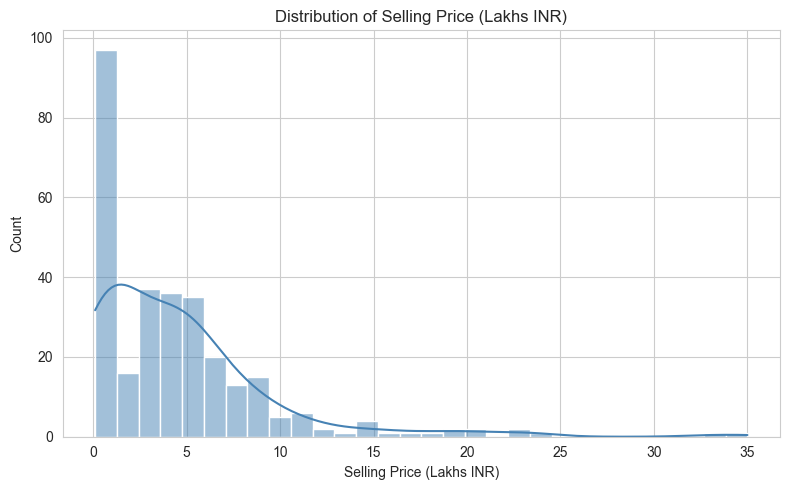

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Selling_Price"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Selling Price (Lakhs INR)")
plt.xlabel("Selling Price (Lakhs INR)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### 5.2 Selling Price vs. Fuel Type

C:\Users\dileepk\AppData\Local\Temp\ipykernel_24688\3260666468.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price", palette="Set2")


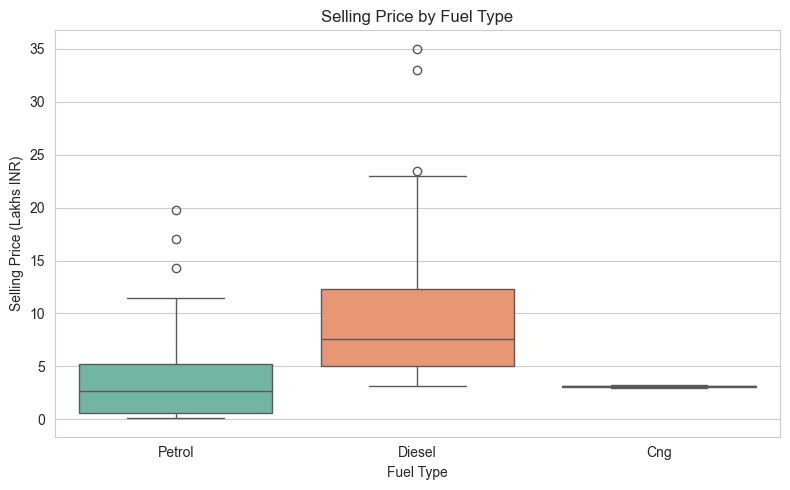

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price", palette="Set2")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (Lakhs INR)")
plt.tight_layout()
plt.show()


### 5.3 Selling Price vs. Car Age

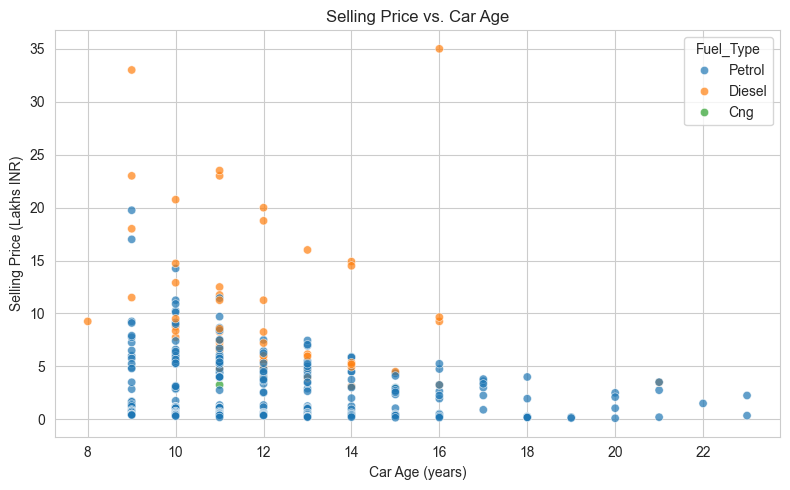

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Car_Age", y="Selling_Price", hue="Fuel_Type", alpha=0.7)
plt.title("Selling Price vs. Car Age")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price (Lakhs INR)")
plt.tight_layout()
plt.show()


### 5.4 A couple of extra views (transmission & top brands)

C:\Users\dileepk\AppData\Local\Temp\ipykernel_24688\4200850961.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Transmission", y="Selling_Price", ax=axes[0], palette="Set3")
C:\Users\dileepk\AppData\Local\Temp\ipykernel_24688\4200850961.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df["Brand"].isin(top_brands)], x="Brand", y="Selling_Price",


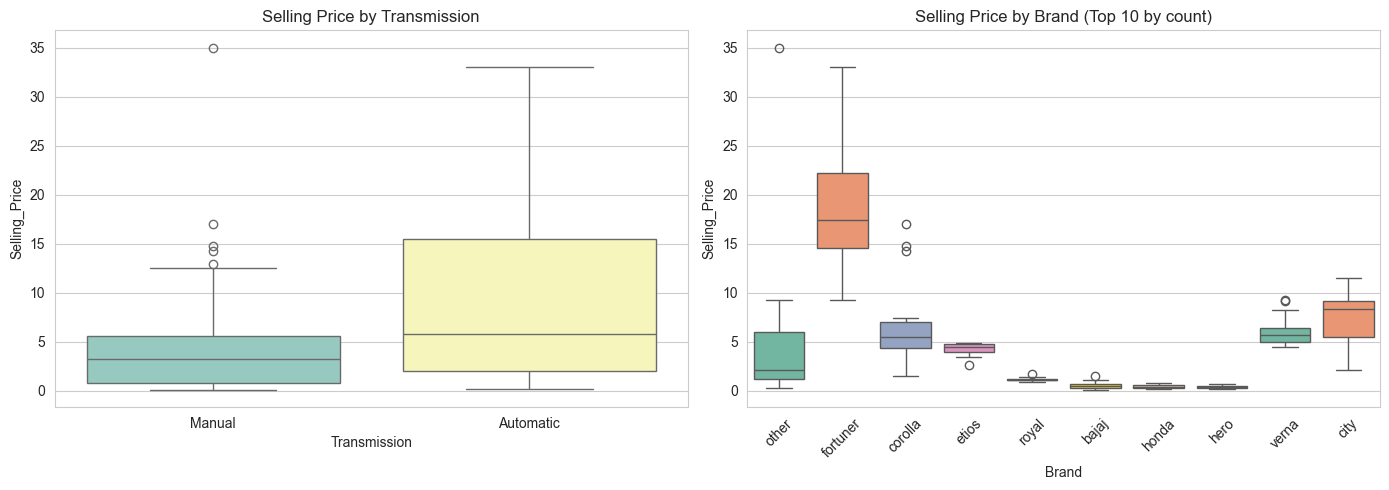

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="Transmission", y="Selling_Price", ax=axes[0], palette="Set3")
axes[0].set_title("Selling Price by Transmission")

top_brands = df["Brand"].value_counts().head(10).index
sns.boxplot(data=df[df["Brand"].isin(top_brands)], x="Brand", y="Selling_Price",
            ax=axes[1], palette="Set2")
axes[1].set_title("Selling Price by Brand (Top 10 by count)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 6. Encode Categorical Variables

`Fuel_Type`, `Seller_Type`, `Transmission`, and `Brand` are one-hot encoded for correlation analysis
and for the models that need purely numeric input.


In [15]:
df_encoded = pd.get_dummies(
    df,
    columns=["Fuel_Type", "Seller_Type", "Transmission", "Brand"],
    drop_first=True
)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head()


Shape after encoding: (299, 41)


,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual,Brand_alto,Brand_amaze,Brand_bajaj,Brand_brio,Brand_ciaz,Brand_city,Brand_corolla,Brand_creta,Brand_dzire,Brand_elantra,Brand_eon,Brand_ertiga,Brand_etios,Brand_fortuner,Brand_grand,Brand_hero,Brand_honda,Brand_i10,Brand_i20,Brand_innova,Brand_jazz,Brand_ktm,Brand_other,Brand_ritz,Brand_royal,Brand_swift,Brand_sx4,Brand_tvs,Brand_verna,Brand_wagon,Brand_xcent,Brand_yamaha
0,3.35,5.59,27000,0,12,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
1,4.75,9.54,43000,0,13,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
2,7.25,9.85,6900,0,9,False,True,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,2.85,4.15,5200,0,15,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
4,4.60,6.87,42450,0,12,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False


## 7. Feature Correlation Heatmap

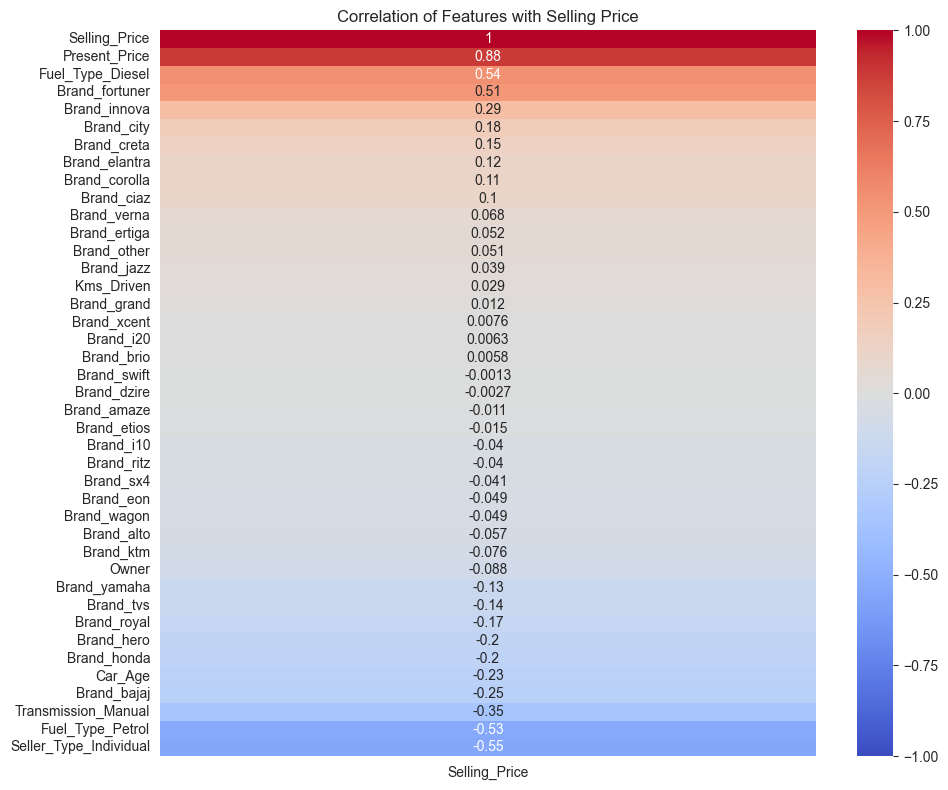

In [16]:
plt.figure(figsize=(10, 8))
corr = df_encoded.corr(numeric_only=True)
sns.heatmap(corr[["Selling_Price"]].sort_values("Selling_Price", ascending=False),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of Features with Selling Price")
plt.tight_layout()
plt.show()


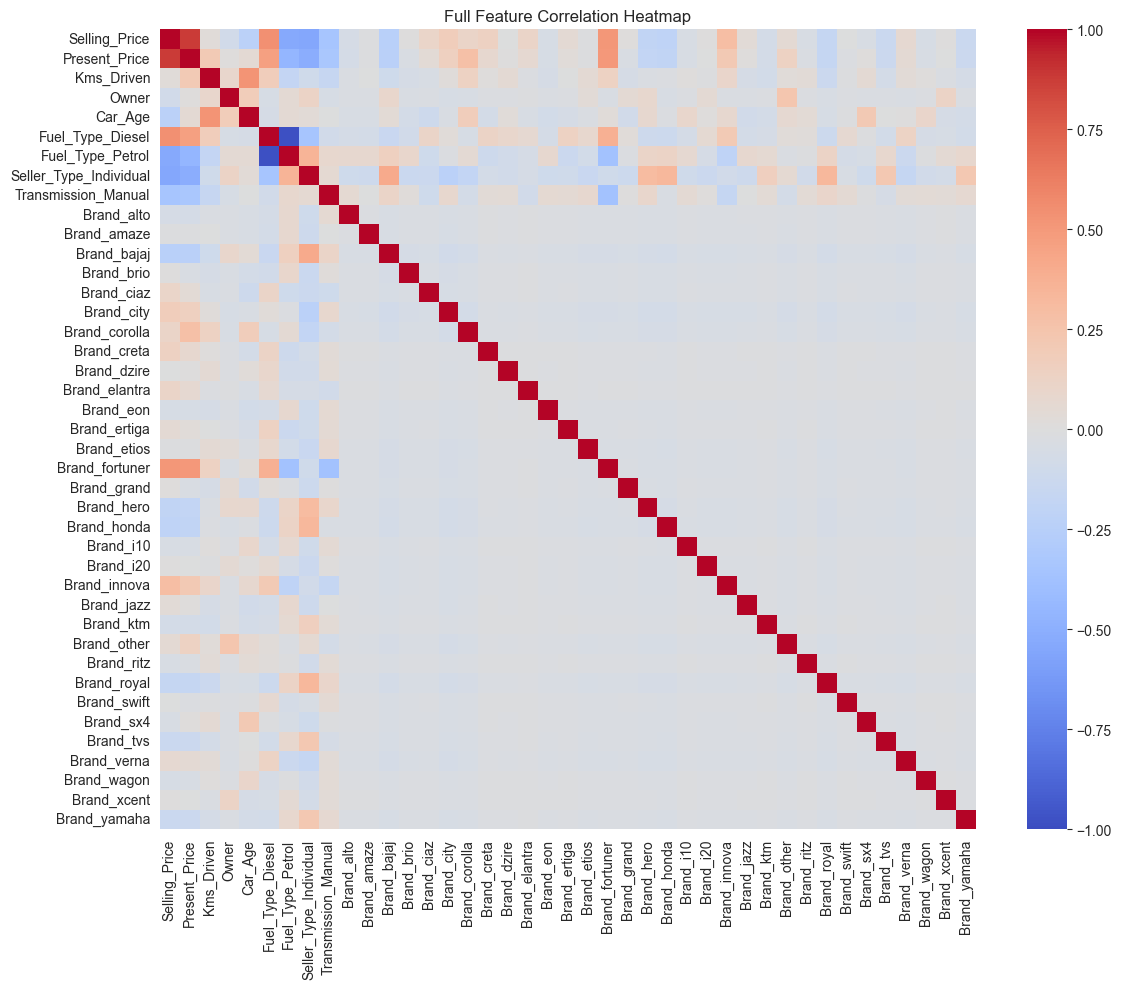

In [17]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Full Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## 8. Train/Test Split

In [18]:
X = df_encoded.drop(columns=["Selling_Price"])
y = df_encoded["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (239, 40)
Test shape: (60, 40)


## 9. Model Training

Three regression models are trained and compared:
1. Linear Regression (baseline)
2. Random Forest Regressor
3. Gradient Boosting Regressor


In [19]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results[name] = {"model": model, "MAE": mae, "RMSE": rmse, "R2": r2, "preds": preds}
    print(f"{name:20s} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R2: {r2:.3f}")


Linear Regression    | MAE: 1.329 | RMSE: 2.458 | R2: 0.766
Random Forest        | MAE: 1.432 | RMSE: 3.604 | R2: 0.496
Gradient Boosting    | MAE: 1.262 | RMSE: 3.236 | R2: 0.594


## 10. Model Evaluation

In [20]:
results_df = pd.DataFrame({
    name: {"MAE": r["MAE"], "RMSE": r["RMSE"], "R2": r["R2"]}
    for name, r in results.items()
}).T.sort_values("R2", ascending=False)

results_df


,MAE,RMSE,R2
Linear Regression,1.328702,2.458417,0.765501
Gradient Boosting,1.261967,3.236461,0.593584
Random Forest,1.432261,3.604294,0.495953


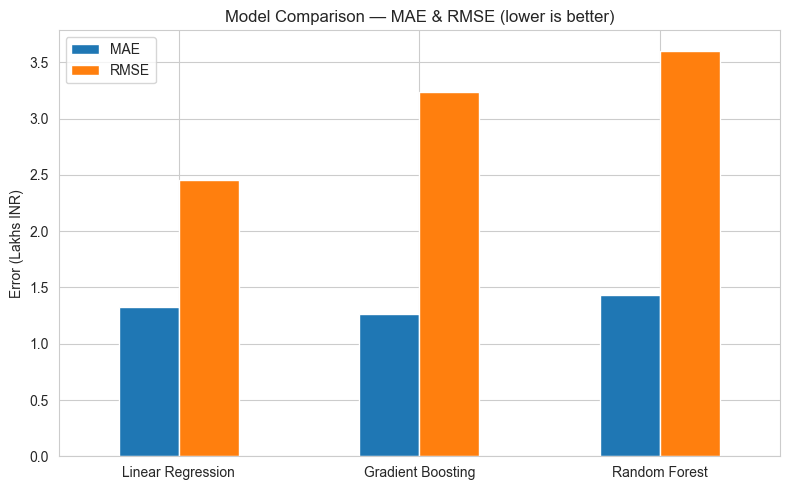

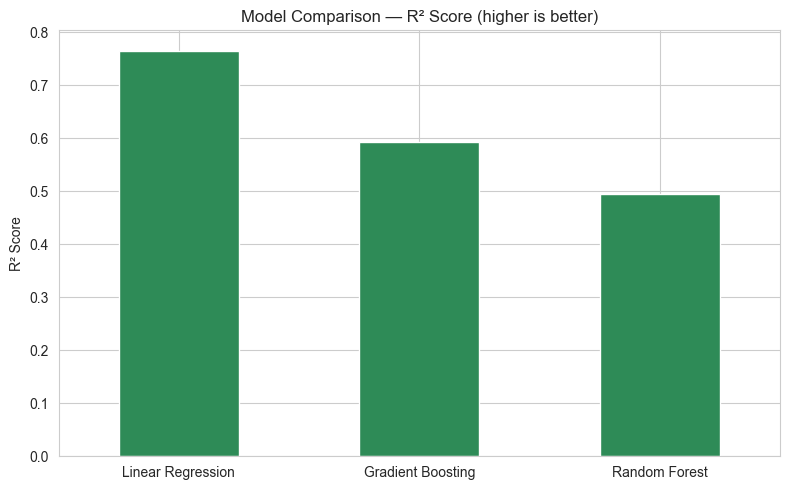

In [21]:
results_df[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 5))
plt.title("Model Comparison — MAE & RMSE (lower is better)")
plt.ylabel("Error (Lakhs INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

results_df["R2"].plot(kind="bar", figsize=(8, 5), color="seagreen")
plt.title("Model Comparison — R² Score (higher is better)")
plt.ylabel("R² Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [22]:
best_model_name = results_df["R2"].idxmax()
best_model = results[best_model_name]["model"]
print(f"Best-performing model: {best_model_name} (R2 = {results_df.loc[best_model_name, 'R2']:.3f})")


Best-performing model: Linear Regression (R2 = 0.766)


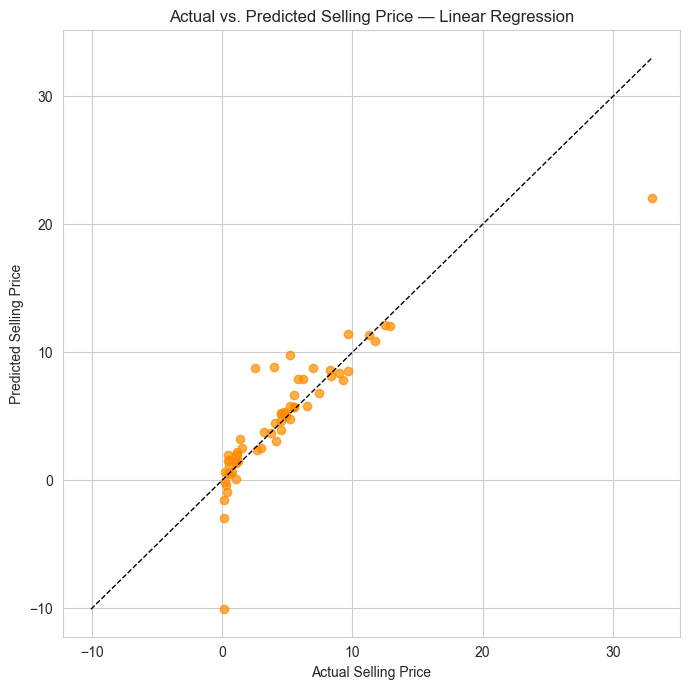

In [23]:
# Actual vs. Predicted for the best model
best_preds = results[best_model_name]["preds"]

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_preds, alpha=0.7, color="darkorange")
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
plt.plot(lims, lims, "k--", linewidth=1)
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title(f"Actual vs. Predicted Selling Price — {best_model_name}")
plt.tight_layout()
plt.show()


## 11. Feature Importance (Best Model)

C:\Users\dileepk\AppData\Local\Temp\ipykernel_24688\1594968535.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefs.values, y=coefs.index, palette="viridis")


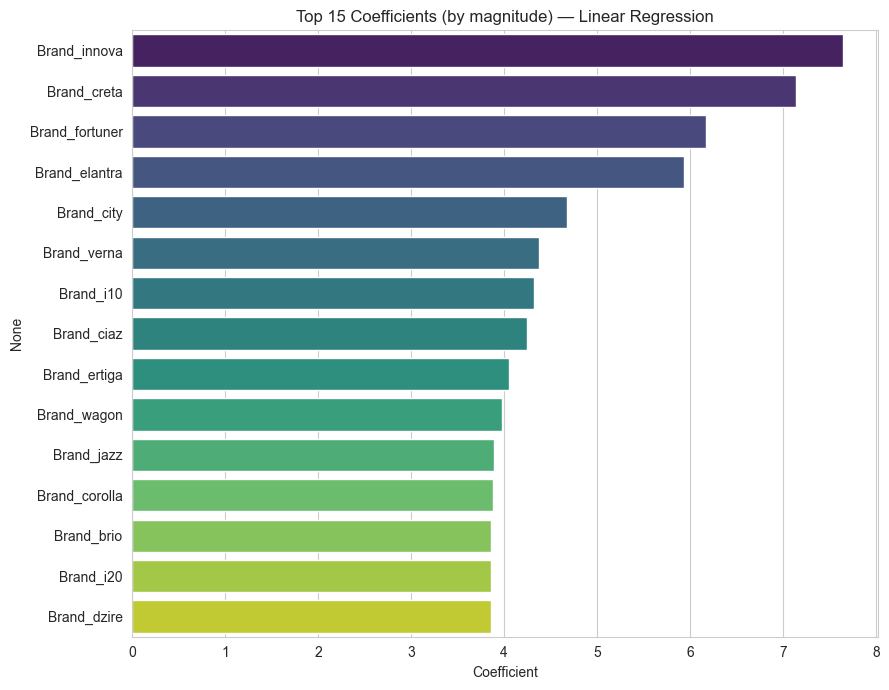

In [24]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns)
    importances = importances.sort_values(ascending=False).head(15)

    plt.figure(figsize=(9, 7))
    sns.barplot(x=importances.values, y=importances.index, palette="viridis")
    plt.title(f"Top 15 Feature Importances — {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    coefs = pd.Series(best_model.coef_, index=X.columns).sort_values(key=abs, ascending=False).head(15)
    plt.figure(figsize=(9, 7))
    sns.barplot(x=coefs.values, y=coefs.index, palette="viridis")
    plt.title(f"Top 15 Coefficients (by magnitude) — {best_model_name}")
    plt.xlabel("Coefficient")
    plt.tight_layout()
    plt.show()


## 12. Conclusion

- `Present_Price` (current ex-showroom price) is the strongest predictor of resale `Selling_Price`,
  which makes intuitive sense — pricier cars new tend to stay pricier used.
- `Car_Age` and `Kms_Driven` are the next most influential features: older, higher-mileage cars sell
  for less.
- Tree-based ensembles (Random Forest / Gradient Boosting) outperform plain Linear Regression here,
  since price depreciation isn't perfectly linear across brands and fuel types.
- Next steps to improve further: gather a larger/more recent dataset (e.g. the full CarDekho dataset
  with `mileage`, `engine`, `max_power`, `seats`), tune hyperparameters via `GridSearchCV`, and try
  log-transforming the skewed `Selling_Price` target.
